# ADoTA model: how to call it

One forward pass of the trained ADoTA network (Stryja, Lathouwers & Perkó, arXiv:2602.04375) for a single pencil beam ("beamlet"),
to show how the model is loaded, what it takes in and what comes out. The code is the unmodified ADoTA repository
(`src/`, commit `050e589`, MIT licence, see `LICENSE`).

The notebook runs without the trained weights: it then uses a randomly initialised network, so only the shapes and units are meaningful, not the dose values.
Put the downloaded model folder into `models/` (see `models/README.md`) and the same cells use the trained network; section 8, a physics check of the network, only runs with trained weights.

| Step | Function (file under `src/`) |
|---|---|
| load the network | `load_model` (`adota/utils.py`); the network itself is `DoTA3D_v3` (`adota/models.py`, `adota/layers/`) |
| arrays to model input | `prepare_input_from_arrays`, `prepare_inputs_from_arrays_batched` (`loaders/dir_based.py`) |
| model output to dose | `postprocess_prediction` (`loaders/dir_based.py`) |
| normalisation constants | `DEFAULT_SCALE` (`adota/config.py`) |

Needs numpy, torch, PyYAML and matplotlib (install notes: `README.md`).

## 0. Setup

The notebook looks for the `src/` folder (the one that holds `src/adota/models.py`) in the current folder, in the folders above it and up to two levels below it, so it works wherever Jupyter or VS Code was started.
If `src/` is somewhere else, set the environment variable `ADOTA_PREDICT_ROOT` to the folder that contains it.
The thread setting keeps shared login nodes happy; set the variable before starting Jupyter to change it.

In [1]:
import os, sys, pathlib

# keep the thread pool small (shared login nodes limit the number of threads); must run before numpy / torch are imported
os.environ.setdefault("OMP_NUM_THREADS", str(min(4, os.cpu_count() or 1)))

import numpy as np, torch
import matplotlib.pyplot as plt

# find the folder that contains src/: $ADOTA_PREDICT_ROOT, the current folder, the folders above it, or up to two levels below it
here = pathlib.Path.cwd()
env_root = os.environ.get("ADOTA_PREDICT_ROOT")
candidates = ([pathlib.Path(env_root)] if env_root else []) + [here, *here.parents]
candidates += [f.parents[2] for pattern in ("*/src/adota/models.py", "*/*/src/adota/models.py") for f in sorted(here.glob(pattern))]
ROOT = next((p for p in candidates if (p / "src" / "adota" / "models.py").exists()), None)
assert ROOT is not None, "no src/ folder found: start in or near adota_predict/, or set ADOTA_PREDICT_ROOT to the folder that contains src/"
sys.path.insert(0, str(ROOT))

from src.adota.config import DEFAULT_SCALE, get_device
from src.adota.models import DoTA3D_v3
from src.adota.utils import load_model
from src.loaders.dir_based import prepare_input_from_arrays, prepare_inputs_from_arrays_batched, postprocess_prediction

print(f"numpy {np.__version__} | torch {torch.__version__} | model code from {ROOT.name}/src")

numpy 1.24.4 | torch 2.12.1+cu130 | model code from adota_predict/src


## 1. The network

A trained model is a folder with two files: `best_model.pth` (the weights) and `hyperparams.json` (the architecture settings). `load_model` builds `DoTA3D_v3` from the JSON, loads the weights and returns the network in eval mode on the chosen device.
The next cell takes the first model folder it finds under `models/` (or the one named in `MODEL_NAME`). If there is none, it builds the same network with random weights, using the example hyperparameters of the ADoTA repository;
then every number below only demonstrates shapes and units.

In [2]:
MODEL_NAME = "DoTA_v3_grid_search_v11"                       # e.g. "DoTA_v3_grid_search_v11"; None = first folder under models/ with best_model.pth and hyperparams.json
device = get_device(0)                  # CUDA device 0 if available, else the CPU; get_device(-1) forces the CPU

found = sorted(p for p in (ROOT / "models").glob("*") if (p / "best_model.pth").exists() and (p / "hyperparams.json").exists())
model_dir = ROOT / "models" / MODEL_NAME if MODEL_NAME else (found[0] if found else None)
trained = model_dir is not None

if trained:
    model = load_model(model_dir / "best_model.pth", model_dir / "hyperparams.json", device)
else:
    HP_EXAMPLE = {"input_shape": [2, 160, 30, 30], "num_levels": 4, "enc_features": 32, "kernel_size": 3, "convolutional_steps": 1,
                  "conv_hidden_channels": 64, "num_transformers": 1, "num_heads": 8, "dropout_rate": 0.1, "causal": True, "num_forward": 0}
    torch.manual_seed(0)
    model = DoTA3D_v3(**HP_EXAMPLE).eval().to(device)

print(f"trained weights from models/{model_dir.name}" if trained else "NO trained weights found: random-weight network (shapes and units only)")
print(f"{type(model).__name__}: {sum(p.numel() for p in model.parameters()):,} parameters, device {device}, training mode {model.training}")
notes = model_dir / "comments.txt" if trained else None               # the notes that come with the published model folder, if present
if notes is not None and notes.exists():
    print("comments.txt in the model folder:", " ".join(notes.read_text().split()))

trained weights from models/DoTA_v3_grid_search_v11
DoTA3D_v3: 14,927,651 parameters, device cuda:0, training mode False
comments.txt in the model folder: Full 71k training. Lungs and Pelvis dataset. 20% validation set size. Static weights for all epochs. No GPR calculation. Adaptive learning rate with patience of 20 epochs and decay of 0.75. Increase model size. Corrected LPS implementation.


## 2. One beamlet: the three inputs

The network predicts the dose of one pencil beam in a box around it. The box has 1 mm voxels and `(60, 60, 320)` voxels: the two lateral axes first and the **depth axis last**.
The beam enters at depth index 0 and runs along the depth axis; voxels in front of the patient surface are air (-1024 HU).
A beamlet is described by three things: `ct_crop` (HU), `flux_crop` (the pencil beam as a Gaussian tube along the beam axis, same shape; the ADoTA repository builds it from the machine's beam data in `src/beamlets/flux.py`, which is not part of this folder; its width is not arbitrary, see section 8) and `energy_mev`.
Below is a synthetic stand-in: 20 mm of air, then water with a 20 mm bone slab at 100 mm depth, a straight beam in the middle, 150 MeV.

In [3]:
D = 320                                                             # depth voxels (1 mm each); lateral: 60 x 60
ct_crop = np.zeros((60, 60, D), dtype=np.float32)                   # HU: water everywhere ...
ct_crop[:, :, :20] = -1024                                          # ... except 20 mm of air in front of the patient
ct_crop[:, :, 100:120] = 1000                                       # ... and a 20 mm bone slab at 100 mm depth

lat = np.arange(60) - 29.5                                          # lateral voxel coordinates, beam axis in the middle
sigma = 5.0                                                         # lateral spread of the pencil beam [voxels = mm]
gauss = np.exp(-(lat[:, None] ** 2 + lat[None, :] ** 2) / (2 * sigma ** 2))
flux_crop = np.repeat(gauss[:, :, None], D, axis=2).astype(np.float32)   # the same Gaussian at every depth (straight beam)

energy_mev = 150.0
print(f"ct_crop {ct_crop.shape} HU {ct_crop.min():.0f}..{ct_crop.max():.0f} | flux_crop {flux_crop.shape} {flux_crop.min():.2g}..{flux_crop.max():.2g} | energy {energy_mev:.0f} MeV")

ct_crop (60, 60, 320) HU -1024..1000 | flux_crop (60, 60, 320) 7.6e-16..0.99 | energy 150 MeV


## 3. From arrays to model input

`prepare_input_from_arrays` does the preprocessing the network was trained with: CT `(HU - min_ct) / (max_ct - min_ct)`, flux min-max normalised **per beamlet** (so its absolute scale does not matter) and energy `(E - min_energy) / (max_energy - min_energy)`.
Then the crop is permuted to depth first `(D, H, W)`, resized trilinearly from the 1 mm crop to the 2 mm model grid `(160, 30, 30)`, and CT and flux are stacked as two channels.
The constants come from `scale`. Pass the one of the model you load: `DEFAULT_SCALE` is what the repository's evaluation scripts use; if `scale` is left out, `loaders/dir_based.py` silently falls back to its own, different constants (for example an energy range of 70-180 MeV instead of 70-270 MeV).

In [4]:
SCALE = DEFAULT_SCALE
print(SCALE)

x, e = prepare_input_from_arrays(ct_crop, flux_crop, energy_mev, scale=SCALE)       # numpy in, torch out
print(f"x {tuple(x.shape)} {x.dtype} | CT channel {x[0].min():.3f}..{x[0].max():.3f} | flux channel {x[1].min():.3f}..{x[1].max():.3f}")
print(f"energy {tuple(e.shape)}: {e.item():.3f} = ({energy_mev:.0f} - {SCALE['min_energy']:.0f}) / ({SCALE['max_energy']:.0f} - {SCALE['min_energy']:.0f})")

{'min_ds': 0.0, 'max_ds': 25277028.0, 'min_ct': -1024, 'max_ct': 3071, 'min_energy': 70.0, 'max_energy': 270.0}
x (2, 160, 30, 30) torch.float32 | CT channel 0.000..0.494 | flux channel 0.000..0.961
energy (1,): 0.400 = (150 - 70) / (270 - 70)


## 4. Forward pass

The network takes a batch: the input `(B, 2, 160, 30, 30)` and the energy `(B, 1)`, both on the network's device, and returns a tuple `(dose, attention)`.
The dose is on the 2 mm model grid, depth first and still normalised. It cannot be negative: every convolution step, the last one of the decoder included, ends in a ReLU, and the only thing after it is an up-sampling that averages neighbouring values (the optional extra ReLU, `last_activation`, is off by default).
The attention weights `(B, heads, 161, 161)` are only returned in eval mode: 160 depth slices plus one energy token.

In [5]:
with torch.no_grad():                                                # inference only
    pred, attention = model(x[None].to(device), e[None].to(device))  # [None] adds the batch dimension
print(f"dose (normalised) {tuple(pred.shape)} | attention {tuple(attention.shape)} | dose range {pred.min().item():.3f}..{pred.max().item():.3f}")

dose (normalised) (1, 1, 160, 30, 30) | attention (1, 4, 161, 161) | dose range 0.000..0.246


## 5. Back to dose

`postprocess_prediction` de-normalises with the dose scale (`dose = pred * (max_ds - min_ds) + min_ds`) and, by default, up-samples trilinearly from the 2 mm model grid to the 1 mm crop grid `(320, 60, 60)`; the result is a numpy array.
The unit, as used throughout the ADoTA repository, is eV/g per proton of this beamlet. The output is depth first `(D, H, W)` while the input crops are depth last, so `np.moveaxis(dose, 0, -1)` brings it into the layout of `ct_crop`.

In [8]:
dose_zyx = np.moveaxis(postprocess_prediction(pred, SCALE)[0, 0], 0, -1)       # (1, 1, 320, 60, 60) -> (60, 60, 320), the layout of ct_crop
print(f"dose {dose_zyx.shape} {dose_zyx.dtype}, max {dose_zyx.max():.3g} eV/g/proton")

dose_model_grid = postprocess_prediction(pred, SCALE, upsample=False)          # stays on the 2 mm model grid
print("without up-sampling:", dose_model_grid.shape)

dose (60, 60, 320) float32, max 6.14e+06 eV/g/proton
without up-sampling: (1, 1, 160, 30, 30)


## 6. Look at it

The central lateral slice of the CT crop and of the predicted dose, and the integrated depth dose (IDD: the dose summed over each lateral plane, per depth).
With the trained network the IDD is expected to show a Bragg peak; with random weights it is noise.

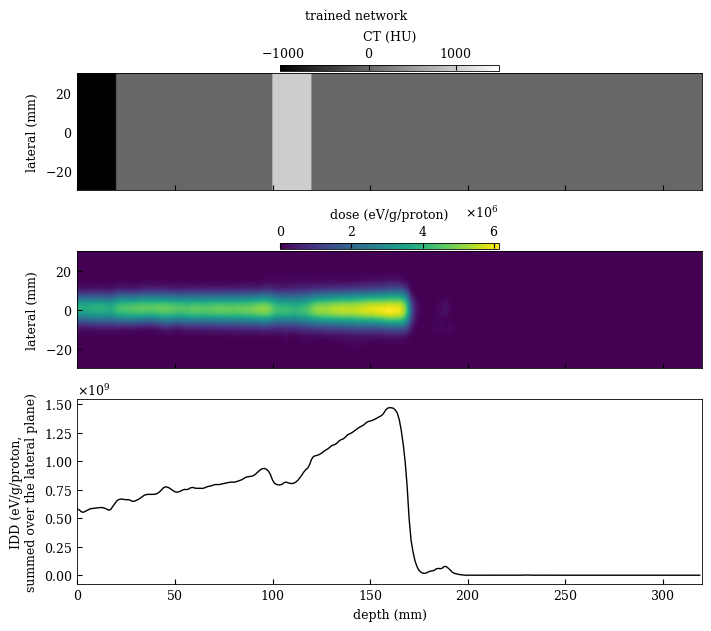

In [9]:
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.linewidth": 0.6, "xtick.direction": "in", "ytick.direction": "in",
                     "axes.formatter.use_mathtext": True})                 # offsets like "x10^7" instead of "1e7"
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(7.0, 6.2), gridspec_kw={"height_ratios": [1, 1, 1.5]}, constrained_layout=True)

im0 = ax[0].imshow(ct_crop[30], extent=[0, D, -30, 30], cmap="gray", vmin=-1024, vmax=1500)
im1 = ax[1].imshow(dose_zyx[30], extent=[0, D, -30, 30], cmap="viridis")
ax[2].plot(np.arange(D), dose_zyx.sum(axis=(0, 1)), lw=1.0, color="k")

fig.colorbar(im0, ax=ax[0], location="top", pad=0.02, shrink=0.35, aspect=40, label="CT (HU)")
fig.colorbar(im1, ax=ax[1], location="top", pad=0.02, shrink=0.35, aspect=40, label="dose (eV/g/proton)")
ax[0].set_ylabel("lateral (mm)"); ax[1].set_ylabel("lateral (mm)")
ax[2].set_ylabel("IDD (eV/g/proton,\nsummed over the lateral plane)"); ax[2].set_xlabel("depth (mm)")
ax[2].set_xlim(0, D)
fig.suptitle("trained network" if trained else "random weights: shapes and units only", fontsize=9)
plt.show()

## 7. Many beamlets in one forward pass

A plan has many spots, so the repository's plan pipeline feeds the network in batches (`batch_size` is 56 beamlets per forward pass by default). `prepare_inputs_from_arrays_batched` is the batched version of step 3 and gives the same numbers beamlet by beamlet.
Here, four energies on the same synthetic crop; the first one is the beamlet from above.

In [ ]:
energies = [150.0, 90.0, 180.0, 240.0]                              # MeV
xb, eb = prepare_inputs_from_arrays_batched([ct_crop] * 4, [flux_crop] * 4, energies, scale=SCALE, device=device)
with torch.no_grad():
    pred_b, _ = model(xb, eb)
dose_b = postprocess_prediction(pred_b, SCALE)                       # (4, 1, 320, 60, 60)

print(f"batch: input {tuple(xb.shape)}, energies {tuple(eb.shape)}, dose {dose_b.shape}")
same = np.allclose(dose_b[0, 0], np.moveaxis(dose_zyx, -1, 0), rtol=1e-4, atol=1e-5 * dose_b.max())
print("first beamlet equals the single-beamlet result:", same)

batch: input (4, 2, 160, 30, 30), energies (4, 1), dose (4, 1, 320, 60, 60)
first beamlet equals the single-beamlet result: True


## 8. Does the trained network behave like a proton beam?

A first plausibility check needs no reference dose. The phantom is homogeneous water behind 20 mm of air, the beam is a straight Gaussian pencil beam, and the energy runs from 70 to 210 MeV (a 220 MeV beam would stop behind the 320 mm crop: 20 mm of air plus 305 mm of range).
Three things are compared with textbook physics.
(1) Range: the depth of the distal 80 % point of the integrated depth dose (R80) against the range of protons in water from the Bethe formula; for protons in water the two agree to within a few millimetres, centimetres would be a failure.
(2) Dose level: the dose summed over the lateral plane in the first centimetres of water against the stopping power. Summed over 1 mm voxels (0.01 cm²), the dose in eV/g has to equal the mass stopping power in eV cm²/g divided by 0.01 cm², which tests the unit and the dose scale.
(3) Energy balance: the dose summed over the whole crop, times the mass of one voxel (1 mm³ of water, 0.001 g), is the energy that the beamlet deposits in the crop per proton. It cannot be larger than the beam energy, and it is expected to be somewhat smaller, because neutrons and gamma rays from nuclear interactions leave the water and the crop is only 60 mm wide.
The network was trained on beamlets whose flux width follows a beam data library, so there the width belongs to the energy. That library is not part of the repository, so the width is left free here and the check is repeated for several values.
This section needs trained weights.

### Reference physics

The Bethe formula for protons in liquid water (mean excitation energy 75 eV, no shell or density correction) gives the stopping power; integrating 1/S over the energy gives the range. `distal_depth_mm` finds R80 on an integrated depth dose.

In [ ]:
ME, MP, I_WATER, ZA_WATER = 0.51099895, 938.27209, 75.0e-6, 10 / 18.01528       # electron and proton rest energy (MeV), mean excitation energy of water (MeV), Z/A of water (mol/g)

def stopping_power(T):                                       # mass stopping power of water for protons of kinetic energy T (MeV), in MeV cm2/g
    gamma = 1 + T / MP
    beta2 = 1 - 1 / gamma ** 2
    t_max = 2 * ME * beta2 * gamma ** 2 / (1 + 2 * gamma * ME / MP + (ME / MP) ** 2)
    return 0.307075 * ZA_WATER / beta2 * (0.5 * np.log(2 * ME * beta2 * gamma ** 2 * t_max / I_WATER ** 2) - beta2)

T_grid = np.geomspace(0.5, 400.0, 20001)                     # MeV; the range below 0.5 MeV is a few micrometres and left out
S_grid = stopping_power(T_grid)
R_grid = np.concatenate([[0.0], np.cumsum(0.5 * (1 / S_grid[1:] + 1 / S_grid[:-1]) * np.diff(T_grid))])    # range in g/cm2, which is cm in water

def csda_range_mm(T):                                        # range of protons of energy T (MeV) in water, in mm
    return 10 * np.interp(T, T_grid, R_grid)

def distal_depth_mm(idd, fraction=0.8):                      # depth where the integrated depth dose has fallen to `fraction` of its maximum, behind the peak
    j = int(np.argmax(idd))
    below = np.nonzero(idd[j:] < fraction * idd[j])[0]
    if below.size == 0:
        return np.nan                                        # no fall-off inside the 320 mm crop
    k = j + below[0]                                         # first voxel below the threshold; voxel k is centred at k + 0.5 mm
    return (k - 1) + (idd[k - 1] - fraction * idd[j]) / (idd[k - 1] - idd[k]) + 0.5

print("range of protons in water [mm], Bethe: " + ", ".join(f"{E} MeV {csda_range_mm(E):.1f}" for E in (100, 150, 200)) + "   (NIST PSTAR: 77.2, 157.7, 259.6)")

range of protons in water [mm], Bethe: 100 MeV 77.1, 150 MeV 157.7, 200 MeV 259.5   (NIST PSTAR: 77.2, 157.7, 259.6)


### Energy sweep

For each flux width the 15 energies go through the network as one batch. The first table is R80 of the network minus the Bethe range (negative: the network stops the beam too early); its last row repeats the sweep with the fallback scale of `loaders/dir_based.py` instead of `DEFAULT_SCALE`. The second table is the dose level, the dose summed over the lateral plane 5-25 mm behind the air gap divided by the stopping-power estimate (1: agreement). The third is the energy balance, the energy deposited in the crop divided by the beam energy (at most 1).

In [ ]:
if trained:
    from src.loaders.dir_based import DEFAULT_SCALE as LOADER_DEFAULT_SCALE        # what the loader uses when scale= is left out
    AIR_MM, SIGMAS = 20, (2.0, 3.0, 4.0, 5.0, 8.0)                                  # air in front of the water (mm); flux widths (mm)
    E_SWEEP = np.arange(70.0, 220.0, 10.0)                                          # MeV, 70 ... 210
    ct_water = np.zeros((60, 60, D), np.float32)
    ct_water[:, :, :AIR_MM] = -1024

    def idd_for(sigma_mm, scale):                                                   # integrated depth dose of every energy: (len(E_SWEEP), 320), eV/g per proton
        g = np.exp(-(lat[:, None] ** 2 + lat[None, :] ** 2) / (2 * sigma_mm ** 2))   # lat: lateral voxel coordinates from section 2
        flux_w = np.repeat(g[:, :, None], D, axis=2).astype(np.float32)
        xs, es = prepare_inputs_from_arrays_batched([ct_water] * len(E_SWEEP), [flux_w] * len(E_SWEEP), list(E_SWEEP), scale=scale, device=device)
        with torch.no_grad():
            pred_s, _ = model(xs, es)
        return postprocess_prediction(pred_s, scale)[:, 0].sum(axis=(2, 3))         # dose summed over the 60 x 60 lateral voxels

    # expected level: the stopping power at the local energy 5-25 mm behind the air gap, in eV/g summed over 0.01 cm2 voxels
    z_cm = (np.arange(AIR_MM + 5, AIR_MM + 25) + 0.5 - AIR_MM) / 10
    expected = np.array([np.mean(stopping_power(np.interp(csda_range_mm(E) / 10 - z_cm, R_grid, T_grid))) * 1e6 / 0.01 for E in E_SWEEP])

    VOXEL_MASS_G = 1e-3                                                             # 1 mm3 of water
    results = {}
    for s in SIGMAS:
        idd = idd_for(s, SCALE)
        results[s] = {"d_r80": np.array([distal_depth_mm(v) for v in idd]) - AIR_MM - csda_range_mm(E_SWEEP),
                      "level": idd[:, AIR_MM + 5:AIR_MM + 25].mean(axis=1) / expected,
                      "balance": idd.sum(axis=1) * VOXEL_MASS_G / (E_SWEEP * 1e6)}               # eV deposited in the crop / eV of the beam
    d_r80_fb = np.array([distal_depth_mm(v) for v in idd_for(3.0, LOADER_DEFAULT_SCALE)]) - AIR_MM - csda_range_mm(E_SWEEP)

    fmt_mm = lambda v: " nan" if np.isnan(v) else f"{v:+4.0f}"
    print("R80 of the network minus the Bethe range of water [mm]   (nan: no fall-off inside the 320 mm crop)")
    print("energy [MeV]".ljust(34) + " ".join(f"{E:4.0f}" for E in E_SWEEP))
    for s in SIGMAS:
        print(f"flux sigma {s:g} mm, DEFAULT_SCALE".ljust(34) + " ".join(fmt_mm(v) for v in results[s]["d_r80"]))
    print("flux sigma 3 mm, loader fallback".ljust(34) + " ".join(fmt_mm(v) for v in d_r80_fb))
    print()
    print("dose summed over the lateral plane 5-25 mm behind the air gap / stopping-power estimate   (1: agreement)")
    print("energy [MeV]".ljust(34) + " ".join(f"{E:4.0f}" for E in E_SWEEP))
    for s in SIGMAS:
        print(f"flux sigma {s:g} mm, DEFAULT_SCALE".ljust(34) + " ".join(f"{v:4.2f}" for v in results[s]["level"]))
    print()
    print("energy deposited in the crop / beam energy   (at most 1)")
    print("energy [MeV]".ljust(34) + " ".join(f"{E:4.0f}" for E in E_SWEEP))
    for s in SIGMAS:
        print(f"flux sigma {s:g} mm, DEFAULT_SCALE".ljust(34) + " ".join(f"{v:4.2f}" for v in results[s]["balance"]))
else:
    print("skipped: this section needs trained weights (put a model folder into models/)")

R80 of the network minus the Bethe range of water [mm]   (nan: no fall-off inside the 320 mm crop)
energy [MeV]                        70   80   90  100  110  120  130  140  150  160  170  180  190  200  210
flux sigma 2 mm, DEFAULT_SCALE     +16   +6   +1   -8   -3   +0   +1   -1   -1   -3   -2   -1   -2   -1   -2
flux sigma 3 mm, DEFAULT_SCALE      +3   +4   -4   -5   -5   -5   -5   -7   -8   -9   -9   -9   -9  -10  -11
flux sigma 4 mm, DEFAULT_SCALE      -2   -2   -3   -4   -4   -4   -6   -5   -5   -5   -5   -4   -2   +2   +4
flux sigma 5 mm, DEFAULT_SCALE      -2   -2   -4   -4   -3   -7  -10   -9   -6   -7  -11  -31  -53  -75  -97
flux sigma 8 mm, DEFAULT_SCALE      +0   -2   -4   -3   -2   -8  -12  -11   -8   -7  -10  -19  -47  -70  -97
flux sigma 3 mm, loader fallback    +3   +7  +17  +31  +46  +62  +82 +103 +125  nan  nan  nan  nan  +32  -15

dose summed over the lateral plane 5-25 mm behind the air gap / stopping-power estimate   (1: agreement)
energy [MeV]                    

### Range, dose level and energy balance against the flux width

(a) The range error, R80 of the network minus the Bethe range, against the energy; the axis stops at -35 mm, the 5 mm and 8 mm curves continue down to -97 mm at 210 MeV (first table). (b) The dose level: the dose summed over the lateral plane 5-25 mm behind the air gap divided by the stopping-power estimate S / 0.01 cm²; 1 means agreement. (c) The energy deposited in the crop divided by the beam energy; the dashed line at 1 is the upper limit.
One line per flux width (σ, lighter is narrower).

In [ ]:
if trained:
    colors = plt.get_cmap("Blues")(np.linspace(0.35, 0.95, len(SIGMAS)))             # narrow spot light, wide spot dark
    fig, ax = plt.subplots(1, 3, figsize=(7.4, 3.0), constrained_layout=True)
    for s, c, m in zip(SIGMAS, colors, "osv^D"):
        for a, key in zip(ax, ("d_r80", "level", "balance")):
            a.plot(E_SWEEP, results[s][key], color=c, marker=m, ms=3, lw=1.0, label=f"{s:g}")
    ax[0].axhline(0, color="0.35", lw=0.6)                                            # agreement
    ax[1].axhline(1, color="0.35", lw=0.6)
    ax[2].axhline(1, color="0.35", lw=0.8, ls="--")                                   # energy conservation: at most 1
    for a, title in zip(ax, ("(a) range", "(b) dose level", "(c) energy balance")):
        a.set_title(title, fontsize=9)
        a.set_xlabel("proton energy (MeV)")
        a.set_xlim(65, 215)
    ax[0].set_ylim(-35, 20)
    ax[1].set_ylim(0.6, 2.6)
    ax[2].set_ylim(0.6, 2.6)
    ax[0].set_ylabel("R80 error (mm)")
    ax[1].set_ylabel("dose level (stopping power = 1)", fontsize=9)
    ax[2].set_ylabel("energy deposited / beam energy", fontsize=9)
    ax[0].legend(title=r"flux $\sigma$ (mm)", frameon=False, fontsize=8, title_fontsize=8, loc="lower left", ncol=2)
    fig.suptitle("trained network, water phantom behind 20 mm of air", fontsize=9)
    plt.show()

### Reading the result

For the published checkpoint `DoTA_v3_grid_search_v11` the result depends on the flux width: the network reads the width as well as the energy input. This fits training on beamlets whose width follows a beam data library, and the paper states that the model is tied to the beam model it was trained with. That library is not part of the repository, so the width that belongs to each energy is not known here; it has to come from the beam model of the training data.

With a 2 mm width the range comes out right from 110 to 210 MeV (R80 within 3 mm of the Bethe range), the dose level is 0.91 to 1.04 of the stopping-power estimate, which is consistent with the unit eV/g per proton, and the crop holds 83 to 93 % of the beam energy.
Other widths shift all three. At 4 mm R80 stays within 6 mm over 70 to 210 MeV, but the dose level is 5 to 19 % high. At 5 mm R80 sits at 185 mm of water for every energy from 170 MeV on, where the Bethe range grows from 196 to 282 mm. At 8 mm the dose is 1.8 to 2.5 times the estimate.
At 70 to 90 MeV every width gives an energy balance above 1 (at least 1.07), which is impossible: at low energy the network deposits more energy than the beam carries, for every width tested.

The last row of the first table repeats the sweep with the loader's fallback scale: the range is then off by 17 mm at 90 MeV and by 125 mm at 150 MeV, and there is no fall-off inside the crop at 160 to 190 MeV. So the energy normalisation of `DEFAULT_SCALE` (70-270 MeV) is the one that goes with this checkpoint. The other constants of the two scales (`max_ds` and `max_ct`) differ by about 2 % and 0.2 %, which this check cannot resolve.
This is a plausibility check, not a validation: there is no reference dose, no patient CT and no gamma pass rate, and the `comments.txt` of the model folder says it was trained on a lungs and pelvis dataset.

## Keep in mind

- **Scale:** the normalisation constants are not stored in the checkpoint. Pass the `scale` of the model you load (`DEFAULT_SCALE` is what the repository's scripts use, and its energy range fits the published `DoTA_v3_grid_search_v11`, see section 8); without `scale=` the loader silently uses different constants, which gives wrong doses if they are not the ones the model was trained with.
- **Axes and grid:** crops are `(lateral, lateral, depth)` with depth last, 1 mm voxels, `(60, 60, 320)`; the dose comes out depth first. Nothing checks the shape or the order: a depth-first `(320, 60, 60)` crop is accepted and gives a wrong input.
  A crop that is already on the 2 mm grid, `(30, 30, 160)`, goes in with `resize=False` (and comes out with `upsample=False`).
- **Energy:** the repository's scale spans 70-270 MeV and the code does not check the range; stay inside the energy range the model was trained on (the paper samples up to 180 MeV for thoracic and up to 270 MeV for abdominal and pelvic anatomies), and note that the energy balance in section 8 is above 1 at 70-90 MeV.
- **Flux width:** the network reacts to the width of the flux channel as well as to the energy (section 8): a width that does not belong to the energy moves the predicted range by centimetres and changes the dose level. Build `flux_crop` as the repository does, from the spot size of the beam data library the model was trained with; that library is not part of the repository.
- **Unit:** eV/g per proton, for one beamlet. A plan dose in Gy needs the number of protons per spot (`src/beamlets/dose_scaling.py` in the repository, not included here).
- **Inputs from patient data:** `ct_crop` and `flux_crop` are made from a patient CT and a plan by the repository's extraction code (`src/beamlets/`: rotation of the CT into the beam's eye view, crop from the entrance point, flux from the machine's beam data). That code is not included here.